# 01 · Data pipeline and exploratory analysis

**Question:** which tropical cyclones have actually threatened Jamaica since 1851, and what does a "typical" threat look like?

My first pass at this (a quick Power BI report) used every 6-hourly track point within 100 nm of the *centre* of the island. Two problems with that:

1. Jamaica is ~235 km long, so a centre-point radius under-counts storms skirting the east or west ends.
2. Counting track points is not counting storms. A slow storm contributes many rows and inflates the totals.

This version measures distance to the **coastline** (Natural Earth 1:10m), interpolates every track to **hourly** positions so a fast mover can't "jump" past the island between fixes, and summarises to **one row per storm**.

The tables are built by `scripts/build_dataset.py`; this notebook explores them.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jhurricane import config, plotting as P

P.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

storms = pd.read_csv(config.DATA_PROCESSED / "storms.csv", parse_dates=["closest_datetime"])
seasons = pd.read_csv(config.DATA_PROCESSED / "seasons.csv")
points = pd.read_csv(config.DATA_PROCESSED / "track_points.csv", parse_dates=["datetime"])
impacts = pd.read_csv(config.DATA_PROCESSED / "impacts.csv")
near = storms[storms["is_near"]].copy()

## Definitions

| Term | Meaning |
|---|---|
| **Near Jamaica** | Track passed within 50 nm (93 km) of the coast while at tropical-storm strength or above (≥ 34 kt) |
| **Intensity near Jamaica** | Highest sustained wind while within 50 nm. It can occur on the far side of the 50 nm ring, so it is a measure of threat rather than of winds felt on land |
| **Landfall** | Interpolated centre crossed the coastline, or HURDAT2 recorded a landfall fix within 5 nm of it |
| **Approach direction** | Where the storm was 24 h before its closest approach, as seen from the centre of the island |

In [2]:
print(f"Storms tracked within 600 nm of Jamaica: {len(storms):,}")
print(f"Storms near Jamaica (TS+ within 50 nm):  {len(near):,}")
print(f"  of which hurricanes: {near['is_hurricane_near'].sum()}, major (Cat 3+): {near['is_major_near'].sum()}")
print(f"Direct landfalls: {storms['jamaica_landfall'].sum()}")
print(f"Years covered: {seasons['year'].min()}-{seasons['year'].max()}")

Storms tracked within 600 nm of Jamaica: 898
Storms near Jamaica (TS+ within 50 nm):  64
  of which hurricanes: 33, major (Cat 3+): 12
Direct landfalls: 23
Years covered: 1851-2025


## Where the threats come from

Plotting all 64 tracks at once gives an unreadable tangle, so instead I group storms by the direction they approached from and average their positions hour by hour, lined up on the moment each one was closest to the coast. The result is one typical route per direction, with the line width showing how many storms took it.

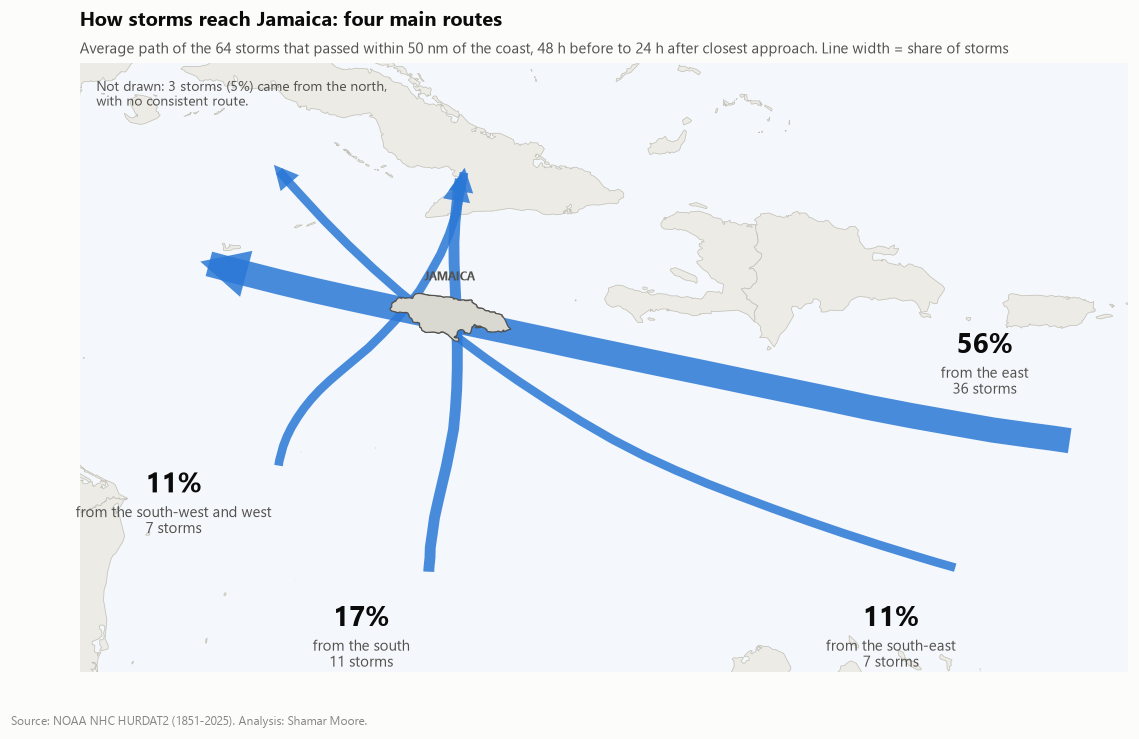

,pathway_label,storms,share
0,From the east,36,0.5625
1,From the south-east,7,0.1094
2,From the south,11,0.1719
3,From the south-west and west,7,0.1094
4,From the north,3,0.0469


In [3]:
pathways = pd.read_csv(config.DATA_PROCESSED / "pathways.csv")
north = pathways[pathways["pathway"] == "N"].iloc[0]

fig, ax = plt.subplots(figsize=(11, 6.6))
fig.subplots_adjust(left=0.02, right=0.98, top=0.88, bottom=0.04)
P.draw_basemap(ax, extent=(-84, -65, 12, 22.5))
P.draw_pathways(ax, pathways, label_at={"E": (-67.6, 17.4), "SE": (-69.3, 12.7), "S": (-78.9, 12.7), "W": (-82.3, 15.0)})
ax.text(-77.3, 18.75, "JAMAICA", ha="center", fontsize=8, color=P.INK_2, weight="bold", zorder=6)
ax.text(-83.7, 22.2, f"Not drawn: {north['storms']} storms ({north['share']:.0%}) came from the north,\nwith no consistent route.",
        fontsize=9, color=P.INK_2, va="top")
ax.set_title("How storms reach Jamaica: four main routes")
P.subtitle(ax, f"Average path of the {len(near)} storms that passed within 50 nm of the coast, "
               "48 h before to 24 h after closest approach. Line width = share of storms")
P.source_note(fig)
fig.savefig(config.FIGURES / "01_pathways_map.png")
plt.show()

pathways.drop_duplicates("pathway")[["pathway_label", "storms", "share"]].reset_index(drop=True)

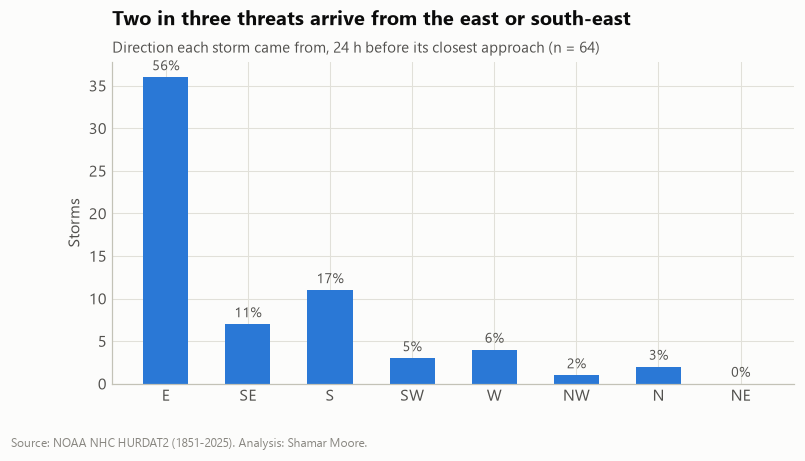

East + south-east share: 67%


In [4]:
order = ["E", "SE", "S", "SW", "W", "NW", "N", "NE"]
approach = near["approach_from"].value_counts().reindex(order, fill_value=0)
share = approach / approach.sum()

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(order, approach.values, color=P.BLUE, width=0.55)
for b, s in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{s:.0%}", ha="center", fontsize=9, color=P.INK_2)
ax.set_ylabel("Storms")
ax.set_title("Two in three threats arrive from the east or south-east")
P.subtitle(ax, f"Direction each storm came from, 24 h before its closest approach (n = {len(near)})")
P.source_note(fig)
fig.savefig(config.FIGURES / "01_approach_direction.png")
plt.show()
print(f"East + south-east share: {share[['E', 'SE']].sum():.0%}")

Most storms ride the trade-wind easterlies through the Caribbean, so the east and south-east dominate. The less common ones are worth noting, though. Late-season storms that form in the south-west Caribbean and move **north-east** (Sandy 2012, Melissa 2025, the November 1912 storm) approach from the S or SW. They tend to reach the south coast, where Kingston and most of the population sit, with little lead time.

## When in the season

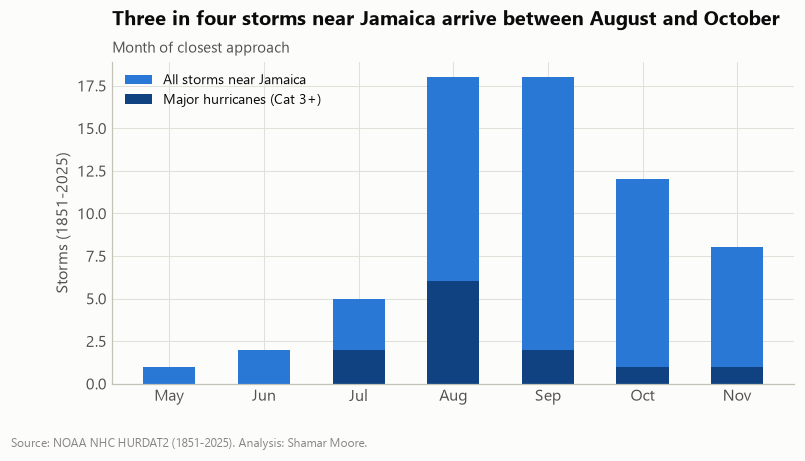

May    0.016
Jun    0.031
Jul    0.078
Aug    0.281
Sep    0.281
Oct    0.188
Nov    0.125
Name: count, dtype: float64


In [5]:
months = near["closest_month"].value_counts().reindex(range(5, 12), fill_value=0)
labels = ["May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]
majors_m = near[near["is_major_near"]]["closest_month"].value_counts().reindex(range(5, 12), fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(labels, months.values, color=P.BLUE, width=0.55, label="All storms near Jamaica")
ax.bar(labels, majors_m.values, color=P.INTENSITY["Cat 4"], width=0.55, label="Major hurricanes (Cat 3+)")
ax.set_ylabel("Storms (1851-2025)")
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Three in four storms near Jamaica arrive between August and October")
P.subtitle(ax, "Month of closest approach")
P.source_note(fig)
fig.savefig(config.FIGURES / "01_seasonality.png")
plt.show()
print((months / months.sum()).round(3).set_axis(labels))

## How strong

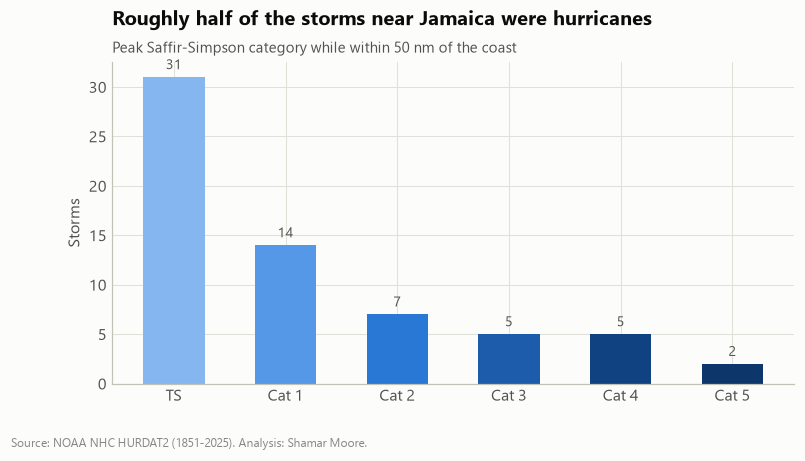

In [6]:
cats = ["TS", "Cat 1", "Cat 2", "Cat 3", "Cat 4", "Cat 5"]
dist = near["category_near_jamaica"].value_counts().reindex(cats, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(cats, dist.values, color=[P.INTENSITY[c] for c in cats], width=0.55)
for b, v in zip(bars, dist.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, str(v), ha="center", fontsize=9, color=P.INK_2)
ax.set_ylabel("Storms")
ax.set_title("Roughly half of the storms near Jamaica were hurricanes")
P.subtitle(ax, "Peak Saffir-Simpson category while within 50 nm of the coast")
P.source_note(fig)
fig.savefig(config.FIGURES / "01_intensity_distribution.png")
plt.show()

In [7]:
cols = ["storm_label", "closest_datetime", "max_wind_near_kt", "min_pressure_near_mb",
        "closest_distance_nm", "approach_from", "jamaica_landfall", "rapid_intensification"]
near.sort_values("max_wind_near_kt", ascending=False)[cols].head(12).reset_index(drop=True)

,storm_label,closest_datetime,max_wind_near_kt,min_pressure_near_mb,closest_distance_nm,approach_from,jamaica_landfall,rapid_intensification
0,Melissa (2025),2025-10-28 18:00:00,165.0,892.0,0.0,SW,True,True
1,Ivan (2004),2004-09-11 04:00:00,145.0,917.0,19.1,SE,False,False
2,Dean (2007),2007-08-19 22:00:00,128.0,926.0,20.3,E,False,True
3,Beryl (2024),2024-07-03 22:00:00,122.0,957.0,13.9,E,False,True
4,Allen (1980),1980-08-06 07:00:00,119.0,953.0,18.6,E,False,True
5,Gilbert (1988),1988-09-12 19:00:00,115.0,956.0,0.0,E,True,True
6,Dennis (2005),2005-07-07 18:00:00,113.0,953.0,25.1,SE,False,True
7,Charlie (1951),1951-08-18 04:00:00,110.0,972.0,0.0,E,True,True
8,Unnamed #02 (1903),1903-08-11 09:00:00,105.0,960.0,0.0,E,True,True
9,Unnamed #04 (1944),1944-08-20 19:00:00,102.0,NaN,0.0,E,True,False


### Takeaways

* **64 storms in 175 years**, about one every 2.7 seasons on average. 33 were hurricanes and 12 were major hurricanes.
* Two in three threats come from the **east / south-east**. The rarer southerly and south-westerly approaches (about one in five) include two of the most damaging storms of the past 15 years.
* **Aug-Oct** accounts for 75% of activity. October alone still carries about one storm in five, and two of the three most recent landfalls (Sandy 2012, Melissa 2025) were October storms. October isn't a quiet tail here.
* The strongest storms ever recorded near Jamaica, **Melissa (165 kt)** and **Ivan (145 kt)**, both occurred in the last 25 years.